# 02 · Busca: recall@1, recall@3 e limiar de recusa

Comparamos duas buscas sobre os mesmos trechos:
- **TF-IDF** (léxica, linha de base) — depende de palavras iguais na pergunta e no trecho.
- **E5 multilíngue** (`intfloat/multilingual-e5-small`, densa) — entende sinônimos ("bueiro" ≈ "boca de lobo").

**recall@k** = fração das 40 perguntas respondíveis do teste em que um trecho do gabarito aparece entre os k primeiros.

**Limiar:** se o score do 1º trecho ficar abaixo dele, a Zela recusa sem chamar o modelo. Ele é escolhido no
**conjunto de treino** (94 perguntas de treino + 25 fora do escopo) pela maior acurácia balanceada — o teste só é
usado para relatar o efeito, nunca para escolher.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath("../src")); sys.path.insert(0, os.path.abspath("../scripts"))
import pandas as pd
from IPython.display import Image, display

In [2]:
%run ../scripts/calibrar_limiar.py --backend tfidf

[tfidf] recall@1 = 0.725 | recall@3 = 0.800  (n = 40)
[tfidf] limiar escolhido = 0.1288 | treino: TPR=0.93 TNR=0.64
[tfidf] no teste: 85% das respondíveis passam | 40% das 'não consta' são barradas


In [3]:
%run ../scripts/calibrar_limiar.py --backend e5

W1112 16:03:38.722000 8304 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

C:\Users\guili\Desktop\zelacidade-genai\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\guili\.cache\huggingface\hub\models--intfloat--multilingual-e5-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

... (9 outputs left out)

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

[e5] recall@1 = 0.825 | recall@3 = 1.000  (n = 40)


[e5] limiar escolhido = 0.8511 | treino: TPR=0.95 TNR=0.88
[e5] no teste: 100% das respondíveis passam | 70% das 'não consta' são barradas


In [4]:
limiar = json.load(open("../avaliacao/limiar.json", encoding="utf-8"))
pd.DataFrame({b: {"recall@1": v["teste"]["recall@1"], "recall@3": v["teste"]["recall@3"], "limiar": v["limiar"],
                  "TPR treino": v["treino"]["tpr"], "TNR treino": v["treino"]["tnr"],
                  "respondíveis passam (teste)": v["teste"]["respondiveis_passam"],
                  "não consta barradas (teste)": v["teste"]["nao_consta_barradas"]} for b, v in limiar.items()}).T

,recall@1,recall@3,limiar,TPR treino,TNR treino,respondíveis passam (teste),não consta barradas (teste)
tfidf,0.725,0.8,0.1288,0.926,0.64,0.85,0.4
e5,0.825,1.0,0.8511,0.947,0.88,1.00,0.7


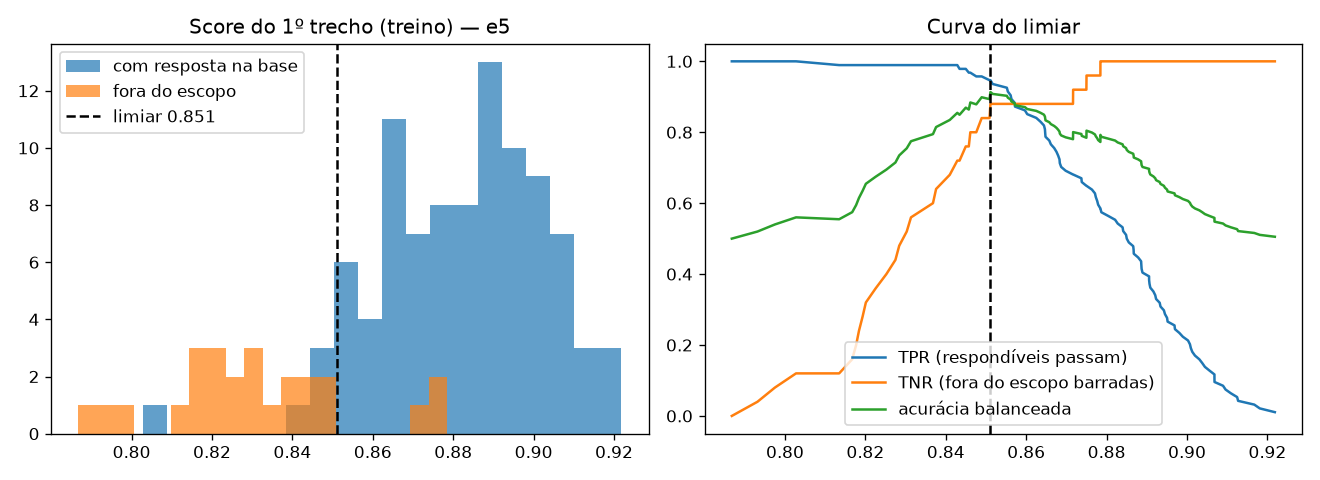

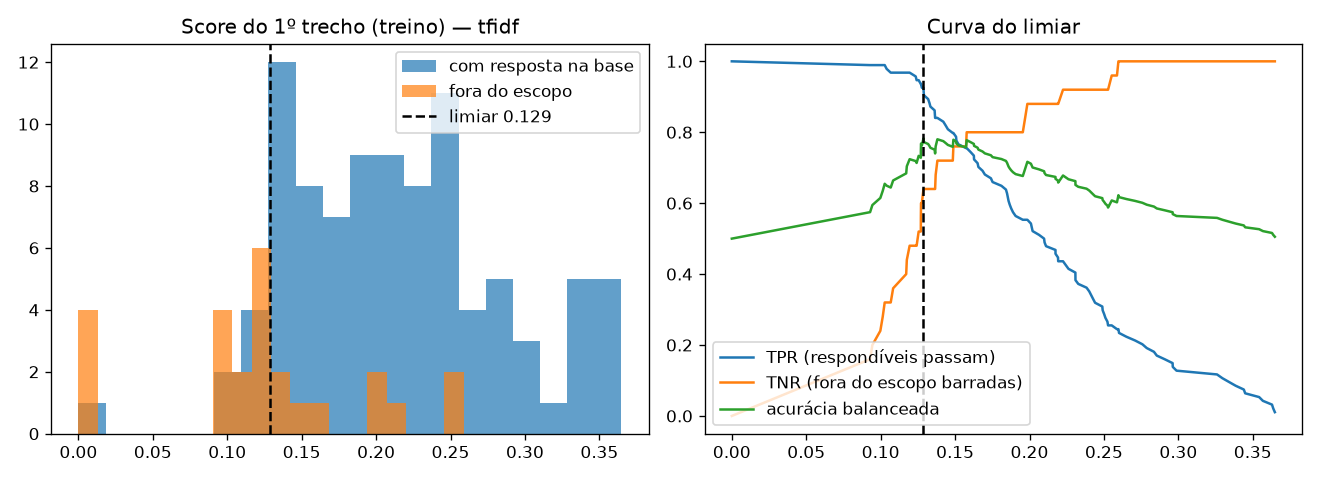

In [5]:
display(Image("../avaliacao/resultados/limiar_e5.png"))
display(Image("../avaliacao/resultados/limiar_tfidf.png"))

## Onde a busca errou (top-3 sem nenhum trecho do gabarito)

In [6]:
for b in ["tfidf", "e5"]:
    d = pd.read_csv(f"../avaliacao/resultados/busca_teste_{b}.csv")
    print(f"--- {b}")
    display(d[(~d.deve_recusar) & (~d["hit@3"])][["id", "relevantes", "top3", "scores"]])

--- tfidf


,id,relevantes,top3,scores
1,Q02,['T002'],"['T024', 'T023', 'T009']","[0.1669, 0.1632, 0.1195]"
3,Q04,['T003'],"['T027', 'T002', 'T001']","[0.1565, 0.1456, 0.1409]"
4,Q05,['T006'],"['T001', 'T005', 'T004']","[0.1986, 0.1924, 0.1691]"
7,Q08,['T008'],"['T046', 'T001', 'T005']","[0.0918, 0.0775, 0.0751]"
12,Q13,['T011'],"['T010', 'T008', 'T046']","[0.1374, 0.114, 0.1026]"
18,Q19,['T017'],"['T015', 'T019', 'T020']","[0.1699, 0.146, 0.0966]"
25,Q26,['T027'],"['T002', 'T017', 'T028']","[0.0947, 0.0898, 0.0655]"
38,Q39,['T043'],"['T004', 'T017', 'T001']","[0.2635, 0.0569, 0.052]"


--- e5


,id,relevantes,top3,scores


## Interpretação

- **Recall (40 respondíveis do teste):** E5 **0,825 / 1,000** (recall@1 / recall@3) contra TF-IDF **0,725 / 0,800**.
  O E5 entende sinônimos e paráfrases; com top-3, toda pergunta respondível recebe ao menos um trecho do gabarito
  no contexto (recall@3 = 1,0 segundo o gabarito).
- **Limiar do E5 = 0,8511**, escolhido só no treino (TPR 0,95, TNR 0,88). No teste, **100% das respondíveis passam**
  e **7 das 10 "não consta" são barradas** sem chamar o modelo (Q43–Q47, Q49 e Q50).
- **Q41, Q42 e Q48 passam do limiar** (score do 1º trecho: 0,8582, 0,8693 e 0,8962) porque são **do mesmo tema** de
  trechos existentes (indenização por buraco, valor da multa de calçada, tapar o buraco por conta própria): o
  limiar mede proximidade de assunto, não se a resposta está no trecho.
- Daí a recusa em **duas camadas**: o limiar barra o que é claramente fora do tema; o modelo (instrução + LoRA)
  precisa recusar quando o contexto é do assunto mas não responde. Resultado dessa segunda camada no notebook 05.